In [1]:
# -------------------------------------------------
# Single cell: imports + setup
# -------------------------------------------------
import os                          # needed for makedirs
import re                          # regular-expression utilities
import pathlib                     # path handling
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations   # for category-pair counting
from collections import Counter      # for frequency counters

# Visualisation style
sns.set_style("whitegrid")
warnings.filterwarnings("ignore")

# Where to save figures: /kaggle/working/images on Kaggle, otherwise the repo's images/ folder
if pathlib.Path("/kaggle/working").exists():
    IMAGES_DIR = pathlib.Path("/kaggle/working/images")
elif pathlib.Path("../images").exists():        # running from notebooks/
    IMAGES_DIR = pathlib.Path("../images")
else:
    IMAGES_DIR = pathlib.Path("images")
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
print("Saving figures to:", IMAGES_DIR.resolve())
# -------------------------------------------------

Saving figures to: /kaggle/working/images











**1. Shape of the Dataset**

In [2]:
import glob
import pathlib

def find_parquet():
    """Kaggle input first, then data/papers.parquet (local clone)."""
    candidates = sorted(pathlib.Path(p) for p in glob.glob("/kaggle/input/**/papers.parquet", recursive=True))
    candidates += [pathlib.Path("data/papers.parquet"), pathlib.Path("../data/papers.parquet")]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(
        "papers.parquet not found. Attach the cleaned-papers dataset on Kaggle "
        "or place the file at data/papers.parquet.")

PARQUET_PATH = find_parquet()
print("Reading:", PARQUET_PATH)

df = pd.read_parquet(PARQUET_PATH)
print("Shape :", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Reading: /kaggle/input/datasets/mohammadibraheem71/arxiv-papers-cleaned/papers.parquet
Shape : (119919, 11)
Columns: ['id', 'title', 'abstract', 'text_raw', 'text_lemma', 'primary_category', 'categories', 'date', 'year', 'month', 'quarter']


,id,title,abstract,text_raw,text_lemma,primary_category,categories,date,year,month,quarter
0,1801.00384,Error-Robust Multi-View Clustering,"In the era of big data, data may come from mul...",Error-Robust Multi-View Clustering. In the era...,error robust multi view clustering era big dat...,cs.LG,cs.LG,2018-01-01 02:42:04,2018,1,2018Q1
1,1801.00388,Beyond Word Embeddings: Learning Entity and Co...,Text representations using neural word embeddi...,Beyond Word Embeddings: Learning Entity and Co...,word embedding learning entity concept represe...,cs.CL,cs.CL cs.AI cs.IR cs.SI,2018-01-01 03:43:30,2018,1,2018Q1
2,1801.00409,PronouncUR: An Urdu Pronunciation Lexicon Gene...,State-of-the-art speech recognition systems re...,PronouncUR: An Urdu Pronunciation Lexicon Gene...,pronouncur urdu pronunciation lexicon generato...,cs.CL,cs.CL,2018-01-01 07:54:09,2018,1,2018Q1
3,1801.00453,Automated rating of recorded classroom present...,Effective presentation skills can help to succ...,Automated rating of recorded classroom present...,automated rating record classroom presentation...,cs.CL,cs.CL cs.AI,2018-01-01 14:56:56,2018,1,2018Q1
4,1801.00470,Script Identification in Natural Scene Image a...,Script identification plays a significant role...,Script Identification in Natural Scene Image a...,script identification natural scene image vide...,cs.CV,cs.CV,2018-01-01 16:42:50,2018,1,2018Q1






**2. Basic Info and Missing Value Check**

In [3]:
print("Dtypes:\n", df.dtypes)
print("\nMissing per column:\n", df.isna().sum())

Dtypes:
 id                          object
title                       object
abstract                    object
text_raw                    object
text_lemma                  object
primary_category            object
categories                  object
date                datetime64[ns]
year                         int64
month                        int64
quarter                     object
dtype: object

Missing per column:
 id                  0
title               0
abstract            0
text_raw            0
text_lemma          0
primary_category    0
categories          0
date                0
year                0
month               0
quarter             0
dtype: int64



**There are zero missing values. This means that data Cleaning stage is successful.**






**3. Duplicate Inspection**

In [4]:
# Duplicate IDs
dup_ids = df[df.duplicated(subset="id", keep=False)]
print("Rows with duplicate ids:", len(dup_ids))

# Near‑identical titles (just for curiosity – Person A already removed them)
def clean_title(t):
    t = str(t).lower()
    t = re.sub(r"\\\[.*?\\\]", "", t)       # remove LaTeX commands
    t = re.sub(r"\\\{.*?\\\}", "", t)
    t = re.sub(r"[^\w\s]", "", t)          # keep only letters/numbers
    return t

df["clean_title"] = df["title"].apply(clean_title)
dup_titles = df[df.duplicated(subset="clean_title", keep=False)]
print("Rows with near‑identical titles:", len(dup_titles))
df.drop(columns=["clean_title"], inplace=True)

Rows with duplicate ids: 0
Rows with near‑identical titles: 0






**There are zero rows with duplicate ids and near-identical titles. Data Cleaning stage succeeded**







**4. Abstract Length Histogram**

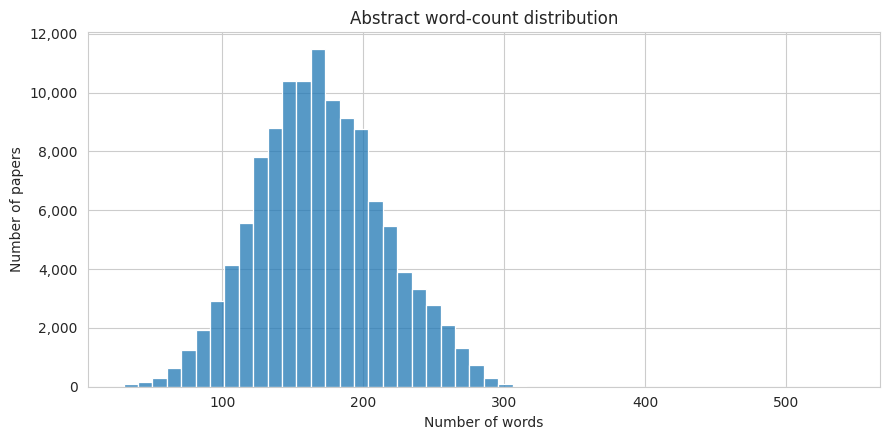

In [5]:
df["abstract_words"] = df["abstract"].fillna("").apply(lambda x: len(x.split()))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(df["abstract_words"], bins=50, kde=False, ax=ax)
ax.set_title("Abstract word-count distribution")
ax.set_xlabel("Number of words")
ax.set_ylabel("Number of papers")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
fig.tight_layout()
fig.savefig(IMAGES_DIR / "abstract_length_histogram.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Abstract length.** Abstract lengths form a roughly bell-shaped curve, slightly skewed to the right, that peaks at about 150–180 words. Most abstracts fall between roughly 100 and 250 words, and very few exceed 300. Extremely short and extremely long abstracts are rare and are kept as legitimate papers (please see the outlier decision in the cleaning notebook for more details).





**5. Title Length Histogram**

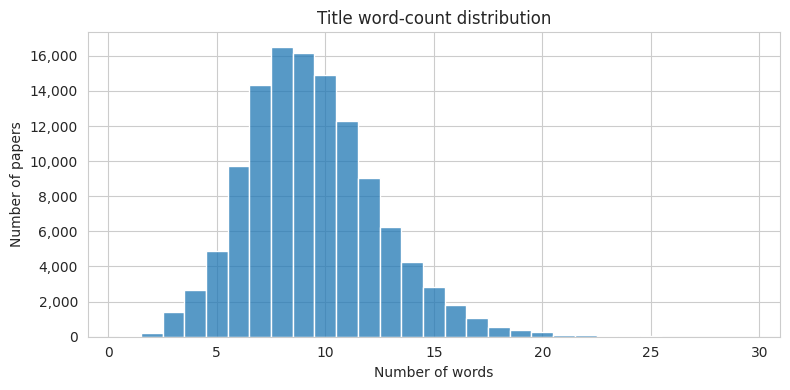

In [6]:
df["title_words"] = df["title"].fillna("").apply(lambda x: len(x.split()))

fig, ax = plt.subplots(figsize=(8, 4))
# discrete=True -> one bar per integer word count (no uneven bins / gaps)
sns.histplot(df["title_words"], discrete=True, kde=False, ax=ax)
ax.set_title("Title word-count distribution")
ax.set_xlabel("Number of words")
ax.set_ylabel("Number of papers")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
fig.tight_layout()
fig.savefig(IMAGES_DIR / "title_length_histogram.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Title length.** Titles are short and fairly symmetric around a median of about 9 words (most fall between 7 and 11), with the most common lengths being 8 and 9 words. A thin right tail runs out to roughly 29 words, and anything above about 17 words is flagged as an outlier by the IQR rule. The year correlation in the heatmap (section 12) is only about 0.11, so titles may be getting slightly longer over 2018–2024, but the effect is very weak.







**6. Boxplot - Abstract vs Title Length**


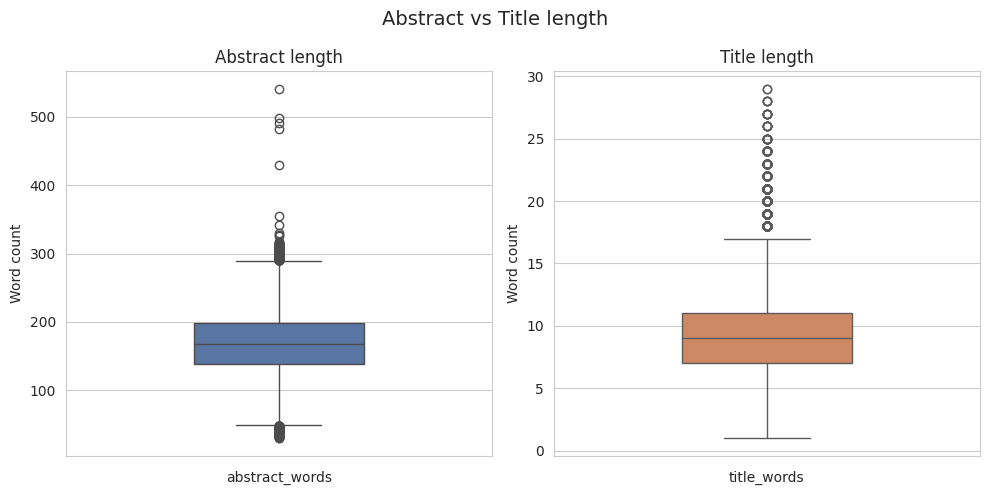

In [7]:
# -------------------------------------------------
# Boxplot: abstract vs title length
# Two panels with independent y-axes, so the title boxplot
# is not squashed by the much larger abstract scale.
# -------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(y=df["abstract_words"], ax=axes[0], color="#4C72B0", width=0.4)
axes[0].set_title("Abstract length")
axes[0].set_xlabel("abstract_words")
axes[0].set_ylabel("Word count")

sns.boxplot(y=df["title_words"], ax=axes[1], color="#DD8452", width=0.4)
axes[1].set_title("Title length")
axes[1].set_xlabel("title_words")
axes[1].set_ylabel("Word count")

fig.suptitle("Abstract vs Title length", fontsize=14)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "abstract_vs_title_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Abstract vs. title length.** Abstracts are far longer than titles: the median abstract is about 168 words (middle half roughly 140–200) against a median title of about 9 words, roughly 18 times longer. The two are drawn on separate axes because the title scale is tiny next to the abstract scale. Abstracts have outliers on both sides (very short ones below ~50 words and a handful of very long ones, up to about 540 words), while title outliers are only on the long side.

**7. Class Balance before the Cap**

In [8]:
# Shared constants for all later plots
CAT_ORDER = sorted(df["primary_category"].unique())
CAT_COLORS = dict(zip(CAT_ORDER, ["#4C72B0", "#DD8452", "#55A868"]))

# Locate and load the uncapped-count CSVs (read-only). They were produced from the ORIGINAL
# arXiv snapshot, not from papers_raw.parquet or papers.parquet (already capped).
# Search order: local results/, the cloned repo on Kaggle, then an attached Kaggle dataset.
import glob

REQUIRED_CSVS = ["uncapped_counts.csv", "uncapped_counts_pivot.csv"]

def find_results_dir():
    candidates = [pathlib.Path("results"), pathlib.Path("../results")]
    candidates += [pathlib.Path(p).parent for p in
                   glob.glob("/kaggle/working/**/results/uncapped_counts.csv", recursive=True)]
    candidates += [pathlib.Path(p).parent for p in
                   glob.glob("/kaggle/input/**/uncapped_counts.csv", recursive=True)]
    for d in candidates:
        if all((d / name).exists() for name in REQUIRED_CSVS):
            return d
    raise FileNotFoundError(
        "Could not find uncapped_counts.csv and uncapped_counts_pivot.csv. Put them in results/, "
        "clone the repo on Kaggle, or attach them to the notebook as a small dataset.")

RESULTS_DIR = find_results_dir()
print("Reading uncapped counts from:", RESULTS_DIR)

uncapped = pd.read_csv(RESULTS_DIR / "uncapped_counts.csv").set_index("primary_category")
uncapped_pivot = pd.read_csv(RESULTS_DIR / "uncapped_counts_pivot.csv", index_col="year")

# Consistency checks (the by-year and totals files are optional extra checks)
assert (uncapped_pivot[CAT_ORDER].sum() == uncapped["papers"].reindex(CAT_ORDER)).all(), "pivot does not add up"
assert (uncapped_pivot[CAT_ORDER].sum(axis=1) == uncapped_pivot["total"]).all(), "yearly totals do not add up"
assert (uncapped["papers"] - uncapped["removed_by_cap"] == uncapped["after_cap"]).all()
by_year_file = RESULTS_DIR / "uncapped_counts_by_year.csv"
if by_year_file.exists():
    by_year = pd.read_csv(by_year_file).groupby("primary_category")["papers"].sum().reindex(CAT_ORDER)
    assert (by_year == uncapped["papers"].reindex(CAT_ORDER)).all(), "by-year counts do not add up"

# Table: uncapped -> after cap -> after cleaning
cleaned = df["primary_category"].value_counts()
balance = pd.DataFrame({
    "uncapped papers": uncapped["papers"],
    "share (%)": uncapped["share_pct"],
    "after cap": uncapped["after_cap"],
    "removed by cap": uncapped["removed_by_cap"],
    "% removed by cap": (uncapped["removed_by_cap"] / uncapped["papers"] * 100).round(1),
    "after cleaning": cleaned,
}).reindex(CAT_ORDER)
balance["removed by cleaning"] = balance["after cap"] - balance["after cleaning"]

count_cols = ["uncapped papers", "after cap", "removed by cap", "after cleaning", "removed by cleaning"]
total = balance[count_cols].sum()
total["share (%)"] = round(balance["share (%)"].sum(), 1)
total["% removed by cap"] = round(total["removed by cap"] / total["uncapped papers"] * 100, 1)
balance.loc["total"] = total
balance[count_cols] = balance[count_cols].astype("int64")

print("\nClass balance: uncapped -> after the 40k cap -> after cleaning")
print(balance.to_string(formatters={c: "{:,}".format for c in count_cols}))
print(f"\ncs.CV / cs.CL before the cap: {uncapped.loc['cs.CV', 'papers'] / uncapped.loc['cs.CL', 'papers']:.2f}x")

Reading uncapped counts from: /kaggle/input/datasets/msohaib82123/uncapped-csvs

Class balance: uncapped -> after the 40k cap -> after cleaning
                 uncapped papers  share (%) after cap removed by cap  % removed by cap after cleaning removed by cleaning
primary_category                                                                                                         
cs.CL                     51,918      21.94    40,000         11,918              23.0         39,980                  20
cs.CV                     96,756      40.89    40,000         56,756              58.7         39,973                  27
cs.LG                     87,945      37.17    40,000         47,945              54.5         39,966                  34
total                    236,619     100.00   120,000        116,619              49.3        119,919                  81

cs.CV / cs.CL before the cap: 1.86x


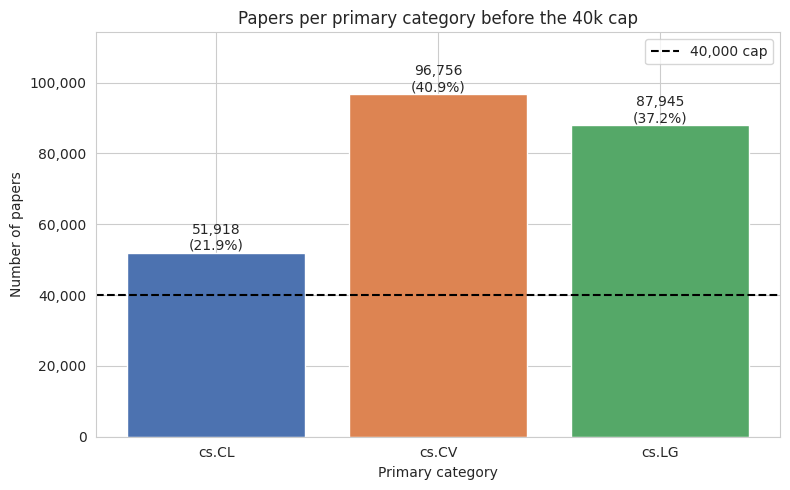

In [9]:
# Uncapped papers per category, with the 40,000 cap as a horizontal line
vals = uncapped.reindex(CAT_ORDER)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(vals.index, vals["papers"], color=[CAT_COLORS[c] for c in vals.index])
ax.axhline(40_000, color="black", linestyle="--", linewidth=1.5, label="40,000 cap")
for bar, n, s in zip(bars, vals["papers"], vals["share_pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({s:.1f}%)",
            ha="center", va="bottom")
ax.set_ylim(0, vals["papers"].max() * 1.18)
ax.set_title("Papers per primary category before the 40k cap")
ax.set_xlabel("Primary category")
ax.set_ylabel("Number of papers")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES_DIR / "2_uncapped_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Class balance before the cap.** The original snapshot is not balanced. Among the three target categories cs.CV has 96,756 papers (40.89%), cs.LG 87,945 (37.17%) and cs.CL 51,918 (21.94%), out of 236,619 in total. Before the cap cs.CV is therefore about 1.86 times as large as cs.CL. The 40k cap keeps 120,000 papers and removes 116,619, which is 49% of the total: 56,756 from cs.CV (59%), 47,945 from cs.LG (55%) and 11,918 from cs.CL (23%). Cleaning then removed only 81 more, which is why the final counts sit just under 40,000. The cleaned dataset is balanced by design, not naturally. The shares above are shares among these three categories, not among all of arXiv.

**8. Papers per Year before the Cap**

Uncapped papers per year and primary category:
      cs.CL  cs.CV  cs.LG  total
year                            
2018  2,974  7,261  4,736 14,971
2019  4,170  8,489  8,840 21,499
2020  5,582 11,000 11,097 27,679
2021  6,578 12,694 13,087 32,359
2022  7,133 14,625 13,754 35,512
2023 10,482 18,901 16,355 45,738
2024 14,999 23,786 20,076 58,861

Growth from the first to the last year (x):
cs.CL    5.04
cs.CV    3.28
cs.LG    4.24
total    3.93


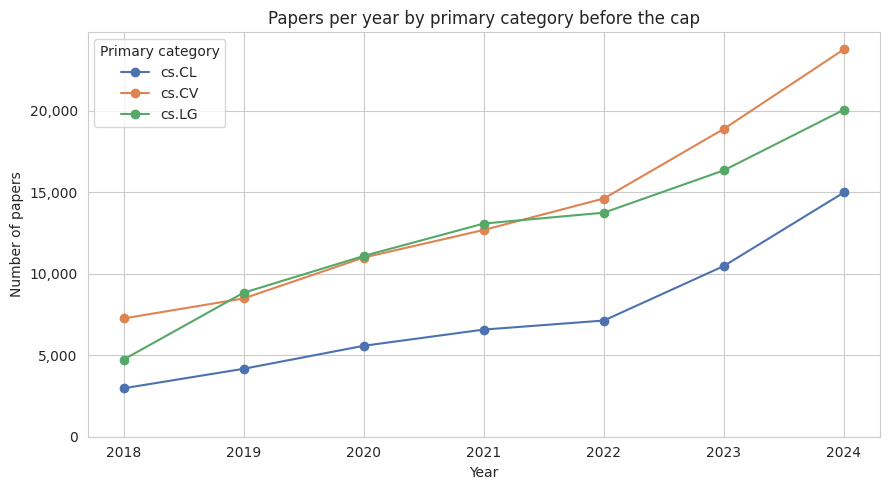

In [10]:
# Uncapped papers per year and primary category (original snapshot)
cols = CAT_ORDER + ["total"]
print("Uncapped papers per year and primary category:")
print(uncapped_pivot[cols].to_string(formatters={c: "{:,}".format for c in cols}))
print("\nGrowth from the first to the last year (x):")
print((uncapped_pivot[cols].iloc[-1] / uncapped_pivot[cols].iloc[0]).round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
for cat in CAT_ORDER:
    ax.plot(uncapped_pivot.index, uncapped_pivot[cat], marker="o", label=cat, color=CAT_COLORS[cat])
ax.set_xticks(uncapped_pivot.index)
ax.set_title("Papers per year by primary category before the cap")
ax.set_xlabel("Year")
ax.set_ylabel("Number of papers")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.legend(title="Primary category")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "2_year_category_trend.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Uncapped year trend.** All three categories grow every year. The yearly totals are 14,971 (2018), 21,499 (2019), 27,679 (2020), 32,359 (2021), 35,512 (2022), 45,738 (2023) and 58,861 (2024), so volume grows about 3.9 times over the period. cs.CL grows fastest (2,974 to 14,999, about 5.0 times), with its largest jumps in 2023 (47%) and 2024 (43%). cs.LG grows about 4.2 times (4,736 to 20,076) and cs.CV about 3.3 times (7,261 to 23,786). The category mix therefore shifts: cs.CV falls from 48.5% of the papers in 2018 to about 40% from 2019 onwards, cs.LG rises from 31.6% in 2018 to 41.1% in 2019 and then falls back to 34.1% in 2024, and cs.CL rises from about 20% to 25.5% in 2024. These are the real volumes from the original snapshot. The yearly counts in the cleaned dataset come from the capped sample, so claims about publication volume over time should use this section.

**9. Class Balance after the 40k Cap**

In [11]:
cat_counts = df["primary_category"].value_counts()
print("Papers per category (capped at 40 k):\n", cat_counts.head(20))
 

Papers per category (capped at 40 k):
 primary_category
cs.CL    39980
cs.CV    39973
cs.LG    39966
Name: count, dtype: int64


**Insight – Class balance after the cap.** The cleaned dataset has about 40,000 papers in each class (39,980, 39,973 and 39,966, a spread of only 14 papers), but it is balanced by design and not naturally. The original proportions are uneven: cs.CV is about 1.86 times as large as cs.CL, with 40.89% of the papers against 37.17% for cs.LG and 21.94% for cs.CL. The cap removed more than half of cs.CV (59%) and cs.LG (55%) and 23% of cs.CL (see section 7). All EDA and modelling conclusions therefore apply to this balanced sample and not to all of arXiv, and any topic share or trend computed on it describes the sample. Class-imbalance handling is not needed for the balanced sample, but the 1:1:1 split must not be presented as the real class distribution.

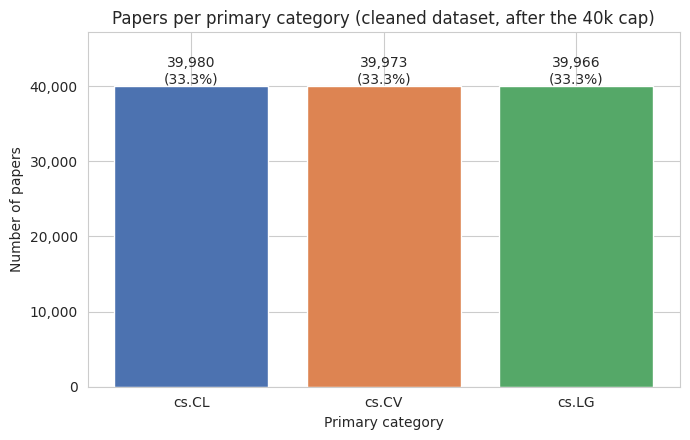

In [12]:
# Class-balance chart of the cleaned dataset (CAT_ORDER and CAT_COLORS are defined in section 7).

counts = df["primary_category"].value_counts().reindex(CAT_ORDER)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(counts.index, counts.values, color=[CAT_COLORS[c] for c in counts.index])
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({n / len(df):.1%})",
            ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_title("Papers per primary category (cleaned dataset, after the 40k cap)")
ax.set_xlabel("Primary category")
ax.set_ylabel("Number of papers")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
fig.tight_layout()
fig.savefig(IMAGES_DIR / "class_balance.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**10. Category Overlap (Cross listed papers)**

In [13]:
# 'categories' is a space-separated string (e.g. "cs.LG cs.CV"),
# so split on whitespace (commas are also handled, just in case).
cat_lists = df["categories"].str.strip().str.split(r"[,\s]+")
df["n_categories"] = cat_lists.str.len()

overlap = df[df["n_categories"] > 1]
print("Papers cross-listed in >1 category:", len(overlap),
      f"({len(overlap) / len(df):.1%} of all papers)")
print("\nDistribution of number of categories per paper:")
print(df["n_categories"].value_counts().sort_index().to_string())

# Top overlapping pairs
from itertools import combinations
from collections import Counter

pair_counts = Counter()
for cats in cat_lists[df["n_categories"] > 1]:
    cats = sorted({c.strip() for c in cats if c.strip()})
    for pair in combinations(cats, 2):
        pair_counts[pair] += 1
top_pairs = pair_counts.most_common(10)
print("\nTop overlapping category pairs:")
for (a, b), n in top_pairs:
    print(f"  {a} + {b}: {n}")

Papers cross-listed in >1 category: 69412 (57.9% of all papers)

Distribution of number of categories per paper:
n_categories
1    50507
2    40728
3    20673
4     6039
5     1625
6      302
7       42
8        3

Top overlapping category pairs:
  cs.AI + cs.LG: 16797
  cs.LG + stat.ML: 14293
  cs.AI + cs.CL: 13009
  cs.CV + cs.LG: 11829
  cs.CL + cs.LG: 10754
  cs.AI + cs.CV: 7499
  cs.CV + eess.IV: 2813
  cs.AI + stat.ML: 2544
  cs.CR + cs.LG: 2195
  cs.CL + cs.CV: 2183


**Insight – Category overlap.** Cross-listing is common: 69,412 of the 119,919 papers (about 58%) list more than one category, so most papers do not belong to a single field. The most frequent pairs are cs.AI + cs.LG (16,797), cs.LG + stat.ML (14,293), cs.AI + cs.CL (13,009), cs.CV + cs.LG (11,829) and cs.CL + cs.LG (10,754), followed by cs.AI + cs.CV (7,499). The remaining pairs in the top 10 are much smaller, at about 2,200–2,800 papers each. Two things stand out:

- cs.LG is in five of the top ten pairs, so it overlaps with the other two target classes (cs.CV and cs.CL) and with neighbouring categories. Expect it to be the hardest class to separate.
- Many pairs involve categories outside our three targets (cs.AI, stat.ML, eess.IV, cs.CR). These papers were selected by their *primary* category, and the other listed categories are secondary.

**11. Frequent Unigrams and Bigrams**

Top 20 unigrams: [('model', 246615), ('learning', 101279), ('base', 97574), ('datum', 94958), ('dataset', 89693), ('image', 88276), ('language', 82464), ('network', 74732), ('training', 66027), ('learn', 62360), ('feature', 57296), ('neural', 53266), ('large', 52055), ('train', 48617), ('information', 44599), ('text', 43321), ('deep', 43030), ('domain', 42652), ('algorithm', 40268), ('framework', 40224)]
Top 20 bigrams: [('neural network', 30389), ('language model', 27116), ('deep learning', 17364), ('large language', 16704), ('real world', 15990), ('machine learning', 12643), ('natural language', 12428), ('pre train', 11606), ('large scale', 10014), ('reinforcement learning', 9933), ('training datum', 8207), ('fine tuning', 8025), ('learning model', 7560), ('language models', 7442), ('deep neural', 7363), ('end end', 7099), ('high quality', 6721), ('object detection', 6676), ('code available', 6595), ('time series', 6500)]


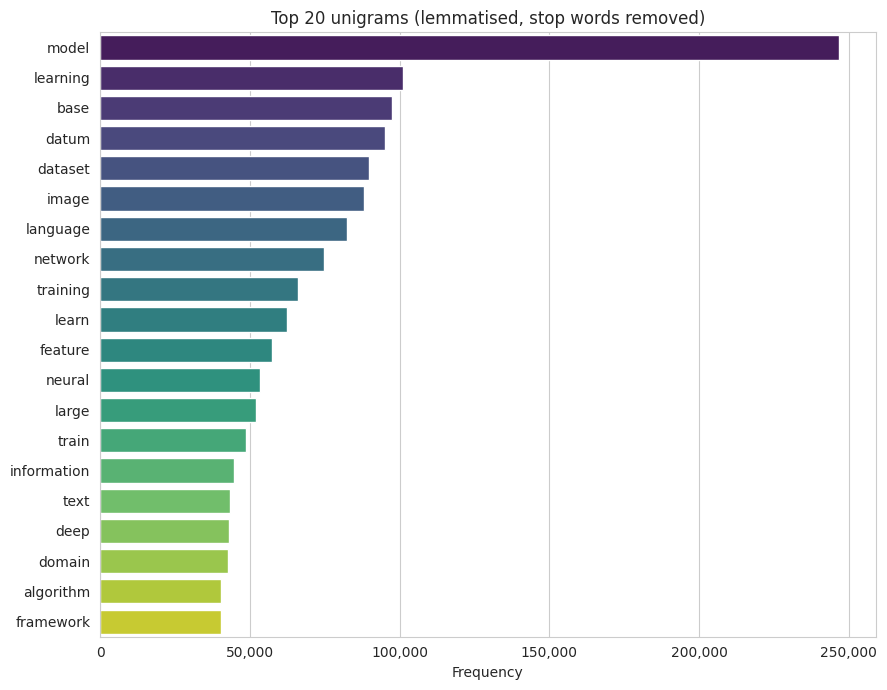

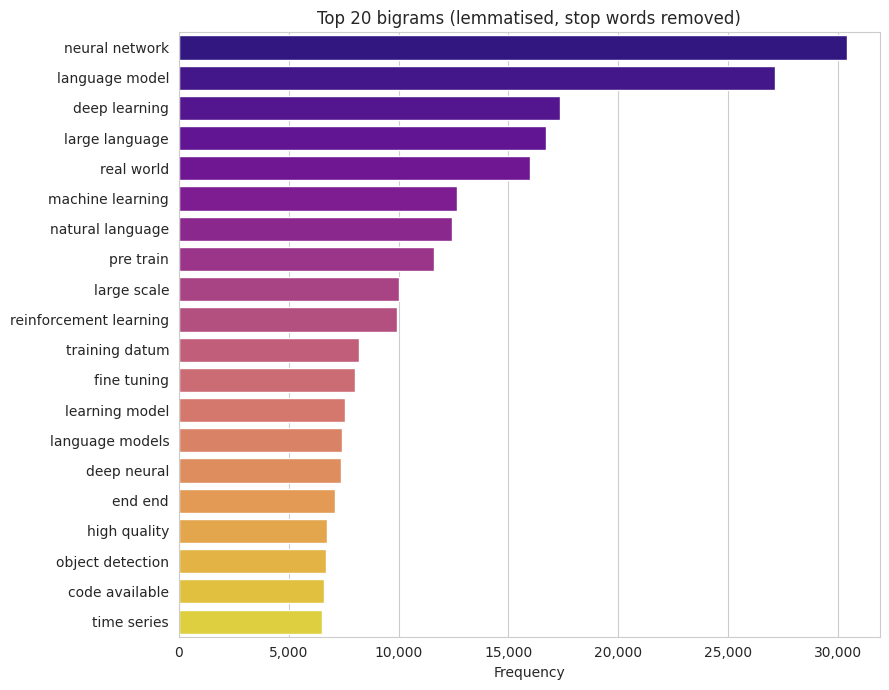

In [14]:
# -------------------------------------------------
# Frequent unigrams & bigrams on the CLEANED text (text_lemma)
# text_lemma is already lower-cased, lemmatised ("model"/"models" -> "model"),
# and has stop words and generic academic words ("paper", "propose", ...) removed,
# so the counts show topical vocabulary rather than words like "the" or "we propose".
# -------------------------------------------------
from collections import Counter

unigram_counter = Counter()
bigram_counter = Counter()

for tokens in df["text_lemma"].fillna("").str.split():
    unigram_counter.update(tokens)
    bigram_counter.update(zip(tokens, tokens[1:]))   # bigrams stay inside one paper

unigrams = unigram_counter.most_common(20)
bigrams = [(f"{a} {b}", n) for (a, b), n in bigram_counter.most_common(20)]

print("Top 20 unigrams:", unigrams)
print("Top 20 bigrams:", bigrams)

# Horizontal bar charts: long labels stay readable and never overlap
# unigram bar chart
uni_labels = [w for w, _ in unigrams]
uni_counts = [c for _, c in unigrams]
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=uni_counts, y=uni_labels, hue=uni_labels, palette="viridis", legend=False, ax=ax)
ax.set_title("Top 20 unigrams (lemmatised, stop words removed)")
ax.set_xlabel("Frequency")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
fig.tight_layout()
fig.savefig(IMAGES_DIR / "frequent_unigrams.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

# bigram bar chart
bi_labels = [b for b, _ in bigrams]
bi_counts = [c for _, c in bigrams]
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=bi_counts, y=bi_labels, hue=bi_labels, palette="plasma", legend=False, ax=ax)
ax.set_title("Top 20 bigrams (lemmatised, stop words removed)")
ax.set_xlabel("Frequency")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
fig.tight_layout()
fig.savefig(IMAGES_DIR / "frequent_bigrams.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Unigrams and bigrams.** These counts use "text_lemma", the same cleaned text that TF-IDF, LDA and the classification baselines will see: lower-cased, lemmatised, with stop words and generic academic words removed. Bigrams are counted within each paper, so no phrase spans two papers. The charts therefore show the topical vocabulary of the corpus instead of function words and abstract boilerplate such as "the", "of" or "we propose".

The most frequent unigram is "model" (about 247,000 occurrences), followed by "learning", "base", "datum", "dataset", "image", "language" and "network". The most frequent bigrams are "neural network" (30,389), "language model" (27,116), "deep learning" (17,364), "large language" (16,704) and "real world" (15,990). The vocabulary is clearly about machine learning, with language and vision terms both visible. Lemmatisation leaves some artefacts: "datum" is the lemma of "data", "base" comes from "based", "pre train" and "end end" come from "pre-trained" and "end-to-end", and both "language model" and "language models" appear as separate bigrams.

Terms that rank high across the whole corpus are shared by all three fields, so they separate the categories poorly on their own. Section 15 compares the vocabulary of each category.

**12. Correlation Heatmap**

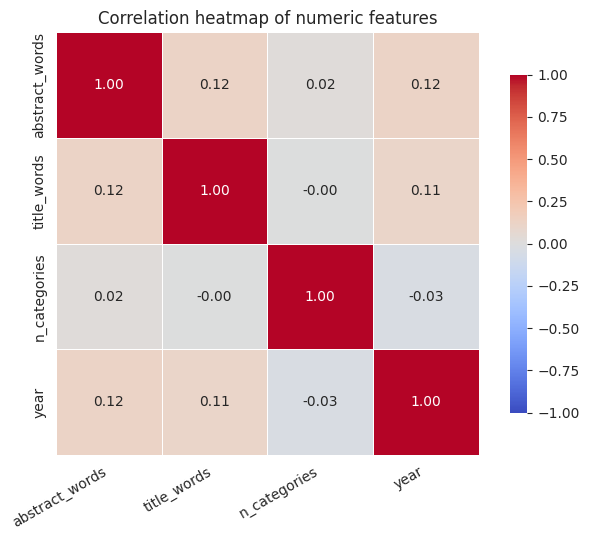

In [16]:
df["year"] = pd.to_numeric(df["year"], errors="coerce")
numeric = df[["abstract_words", "title_words", "n_categories", "year"]].dropna()
corr = numeric.corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)

# If a column were constant its correlation would be undefined (NaN);
# label such cells explicitly instead of leaving them blank.
for i, row in enumerate(corr.index):
    for j, col in enumerate(corr.columns):
        if np.isnan(corr.loc[row, col]):
            ax.text(j + 0.5, i + 0.5, "n/a", ha="center", va="center", color="gray")

ax.set_title("Correlation heatmap of numeric features")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "corr_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Correlations.** Abstract length, title length and year are all weakly and positively correlated (about 0.11–0.12): later papers are slightly longer, and longer titles go with slightly longer abstracts. "n_categories" is essentially uncorrelated with everything else (between -0.03 and 0.02), so cross-listing does not depend on paper length or year. No pair is strong enough to raise multicollinearity concerns.

**13. Time Trends in the Cleaned Sample**

Papers per year and primary category:
primary_category  cs.CL  cs.CV  cs.LG  total
year                                        
2018               2276   2975   2122   7373
2019               3212   3446   3937  10595
2020               4281   4504   5002  13787
2021               5067   5374   6086  16527
2022               5452   6075   6259  17786
2023               8115   7754   7399  23268
2024              11577   9845   9161  30583


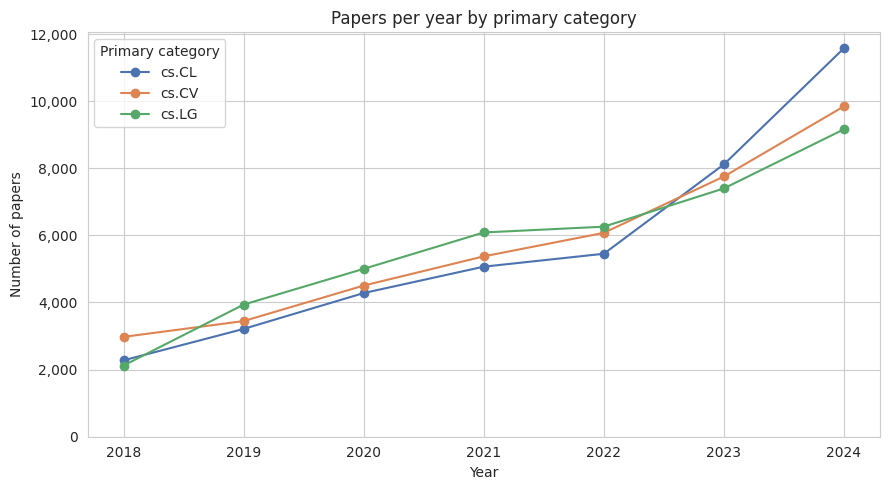

In [17]:
# Papers per year and primary category (counts of the capped sample)
yearly = (df.groupby(["year", "primary_category"]).size()
            .unstack("primary_category").reindex(columns=CAT_ORDER))
print("Papers per year and primary category:")
print(yearly.assign(total=yearly.sum(axis=1)).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
for cat in CAT_ORDER:
    ax.plot(yearly.index, yearly[cat], marker="o", label=cat, color=CAT_COLORS[cat])
ax.set_xticks(yearly.index)
ax.set_title("Papers per year by primary category")
ax.set_xlabel("Year")
ax.set_ylabel("Number of papers")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.legend(title="Primary category")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "time_trends_papers_per_year.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Time trends in the cleaned sample.** The cleaned sample grows from 7,373 papers in 2018 to 30,583 in 2024 (about 4.1 times), close to the 3.9 times growth in the uncapped data. Within each category the cap kept a nearly constant share of every year (about 77% of cs.CL, 41% of cs.CV and 45% of cs.LG), so the growth shape of each category is preserved. The kept share differs between categories, however, so the ranking between them is not: in the sample cs.CL is the largest category in 2023 (8,115) and 2024 (11,577), while in the uncapped data it is the smallest in every year and cs.CV is the largest in 2024 (23,786 against 14,999). The cs.CL surge in the sample is therefore exaggerated by the cap, and claims about which category is largest or growing fastest should use section 8.

Text length also rises over time. Mean abstract length goes from 156.5 words in 2018 to 174.5 in 2024 (about 11% longer) and flattens after 2023. Mean title length goes from 9.0 to 9.9 words after a small dip in 2019. Both changes are small next to the spread within a single year (the middle half of abstracts is about 60 words wide and of titles about 4 words wide), and the y-axes of these charts do not start at zero, which makes the lines look steeper than the changes are.

Mean length per year (words):
      abstract_words  title_words
year                             
2018           156.5          9.0
2019           159.6          8.9
2020           165.0          9.1
2021           168.4          9.2
2022           171.9          9.3
2023           174.2          9.6
2024           174.5          9.9


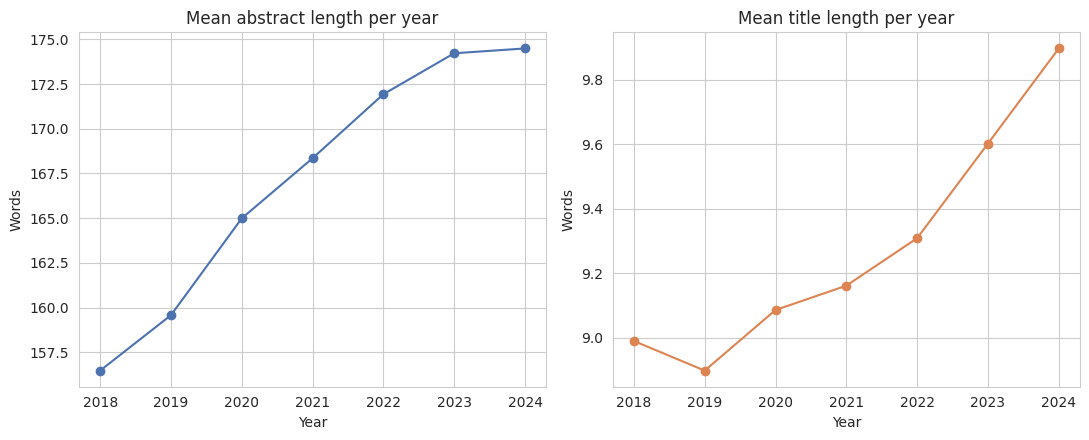

In [18]:
# Mean abstract and title length per year
length_by_year = df.groupby("year")[["abstract_words", "title_words"]].mean()
print("Mean length per year (words):")
print(length_by_year.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(length_by_year.index, length_by_year["abstract_words"], marker="o", color="#4C72B0")
axes[0].set_title("Mean abstract length per year")
axes[0].set_ylabel("Words")
axes[1].plot(length_by_year.index, length_by_year["title_words"], marker="o", color="#DD8452")
axes[1].set_title("Mean title length per year")
axes[1].set_ylabel("Words")
for ax in axes:
    ax.set_xticks(length_by_year.index)
    ax.set_xlabel("Year")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "time_trends_length_by_year.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Time trends in the cleaned sample.** The first chart shows papers per year in the cleaned, capped dataset, and the second shows mean abstract and title length per year. The yearly counts describe this sample only, so real volume trends are in section 8. The year-length correlation is weak (about 0.11 to 0.12 in the heatmap), so any year-to-year change in mean length is small compared with the spread of lengths within each year.

**14. Per-Category Text Length**

Length per category (words):
                 abstract_words        title_words       
                           mean median        mean median
primary_category                                         
cs.CL                     159.0  156.0         9.8    9.0
cs.CV                     178.3  177.0         9.4    9.0
cs.LG                     171.8  170.0         9.1    9.0


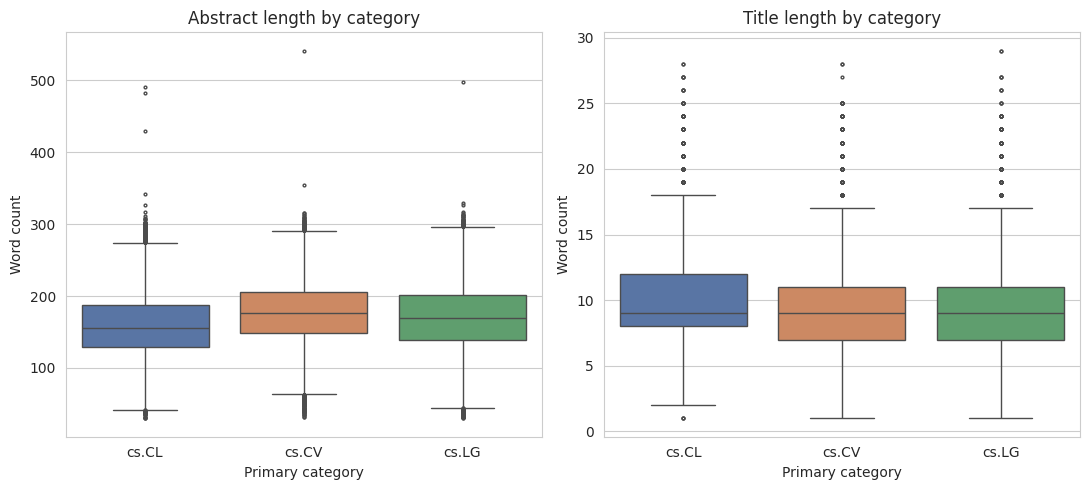

In [19]:
# Abstract and title length for each primary category
length_summary = (df.groupby("primary_category")[["abstract_words", "title_words"]]
                    .agg(["mean", "median"]).round(1))
print("Length per category (words):")
print(length_summary.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, col, title in zip(axes, ["abstract_words", "title_words"],
                          ["Abstract length by category", "Title length by category"]):
    sns.boxplot(data=df, x="primary_category", y=col, order=CAT_ORDER,
                hue="primary_category", palette=CAT_COLORS, legend=False,
                fliersize=2, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Primary category")
    ax.set_ylabel("Word count")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "per_category_lengths.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Per-category text length.** Abstract length differs only a little by category. cs.CL has the shortest abstracts (mean 159.0, median 156 words), cs.CV the longest (mean 178.3, median 177) and cs.LG sits in between (mean 171.8, median 170), so the medians of the two extremes are about 21 words apart. That gap is small next to the spread inside each category: the boxes are about 60 words wide and overlap heavily, and every category's median lies inside the middle half of the other two. Titles are almost identical, with a median of 9 words in all three categories. cs.CL has slightly longer titles on average (9.8 words against 9.4 for cs.CV and 9.1 for cs.LG), and its box reaches higher (about 8 to 12 words against 7 to 11). Every category has long-title outliers up to about 28 words and a few extreme abstracts of roughly 430 to 540 words.

Text length can therefore add a small amount of signal but cannot separate the categories on its own. Because cs.CV abstracts are the longest, an embedding model with a 256-token limit will likely truncate slightly more of them.

**15. Per-Category Terms**

Top 10 most frequent unigrams per category:
        cs.CL     cs.CV      cs.LG
1       model     image      model
2    language     model   learning
3     dataset   dataset      datum
4        base      base    network
5        text   feature       base
6       datum   network      learn
7       large    object  algorithm
8    training  learning     neural
9   knowledge     datum   training
10       llms     video      graph


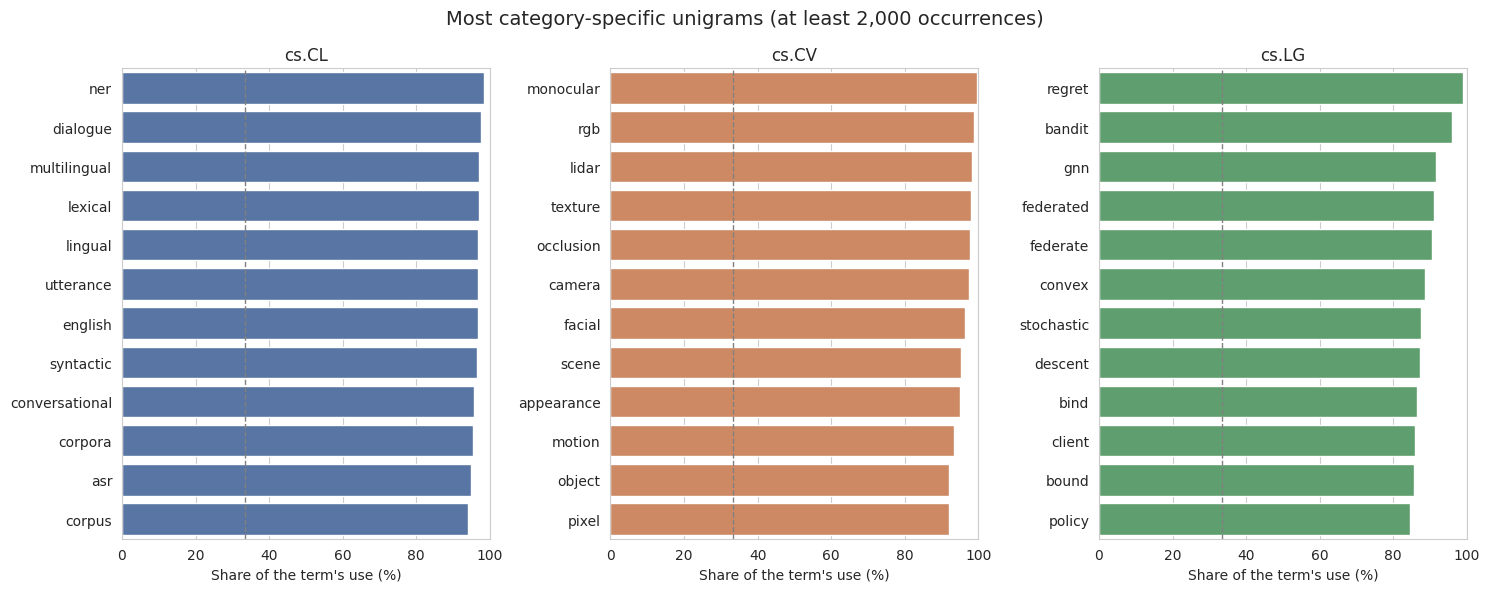

In [20]:
# Per-category vocabulary on the cleaned text (text_lemma).
# For each term we compute its use per paper in every category and then each
# category's share of that total. With balanced classes, an even split is 33.3%,
# so a high share means the term is specific to that category.
from sklearn.feature_extraction.text import CountVectorizer

cat_sizes = df["primary_category"].value_counts()

def category_term_counts(n, min_df=50):
    """Occurrences of every unigram (n=1) or bigram (n=2) in each category."""
    vec = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                          ngram_range=(n, n), min_df=min_df)
    X = vec.fit_transform(df["text_lemma"].fillna(""))
    return pd.DataFrame(
        {cat: np.asarray(X[(df["primary_category"] == cat).values].sum(axis=0)).ravel()
         for cat in CAT_ORDER},
        index=vec.get_feature_names_out())

def distinctive_terms(counts, min_total, top_n=12):
    """Top terms per category by share, ignoring rare terms (< min_total occurrences)."""
    rate = counts / cat_sizes.reindex(CAT_ORDER)
    share = rate.div(rate.sum(axis=1), axis=0)
    keep = counts.sum(axis=1) >= min_total
    return {cat: share.loc[keep, cat].nlargest(top_n) for cat in CAT_ORDER}

def plot_distinctive(top, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))
    for ax, cat in zip(axes, CAT_ORDER):
        s = top[cat]
        sns.barplot(x=s.values * 100, y=list(s.index), color=CAT_COLORS[cat], ax=ax)
        ax.axvline(100 / len(CAT_ORDER), color="gray", linestyle="--", linewidth=1)
        ax.set_title(cat)
        ax.set_xlabel("Share of the term's use (%)")
        ax.set_ylabel("")
        ax.set_xlim(0, 100)
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    fig.savefig(IMAGES_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()      # display below the cell
    plt.close(fig)

# Unigrams: most frequent terms per category, then the most category-specific ones
uni_counts = category_term_counts(1)
frequent = pd.DataFrame({cat: uni_counts[cat].nlargest(10).index for cat in CAT_ORDER})
frequent.index = range(1, len(frequent) + 1)
print("Top 10 most frequent unigrams per category:")
print(frequent.to_string())

top_uni = distinctive_terms(uni_counts, min_total=2000)
plot_distinctive(top_uni, "Most category-specific unigrams (at least 2,000 occurrences)",
                 "per_category_distinctive_unigrams.png")

**Insight – Per-category terms.** The most frequent unigrams overlap heavily. "model", "base" and "datum" (the lemma of "data") are in the top 10 of all three categories, and "dataset", "network", "learning" and "training" each appear in two. Only a few frequent words point to a field: language, text, large, knowledge and llms for cs.CL; image, feature, object and video for cs.CV; and learn, algorithm, neural and graph for cs.LG.

The category-specific charts are much clearer. Almost every listed term has 85% to 99% of its use in a single category, far above the 33.3% of an even split.

- cs.CL: NLP vocabulary such as ner, dialogue, multilingual, utterance, corpus and asr, and bigrams such as machine translation, relation extraction, reading comprehension, dialogue system and "name entity" (named entity).
- cs.CV: visual vocabulary such as monocular, rgb, lidar, occlusion and pixel, and bigrams such as instance segmentation, depth estimation, pose estimation, optical flow and object tracking.
- cs.LG: learning-theory and optimisation terms such as regret, bandit, convex, stochastic and descent, federated learning (federated, client), gnn, reinforcement learning (policy gradient, value function, markov decision), and also time series and differential equation.

The cs.LG terms have slightly lower shares than the other two categories (the lowest, "policy", is about 85%), which is consistent with cs.LG overlapping more with the other categories. Some lemmatiser artefacts appear: "federated" and "federate" are listed separately, "bind" probably comes from "bound", and "series datum" stands for "time series data".

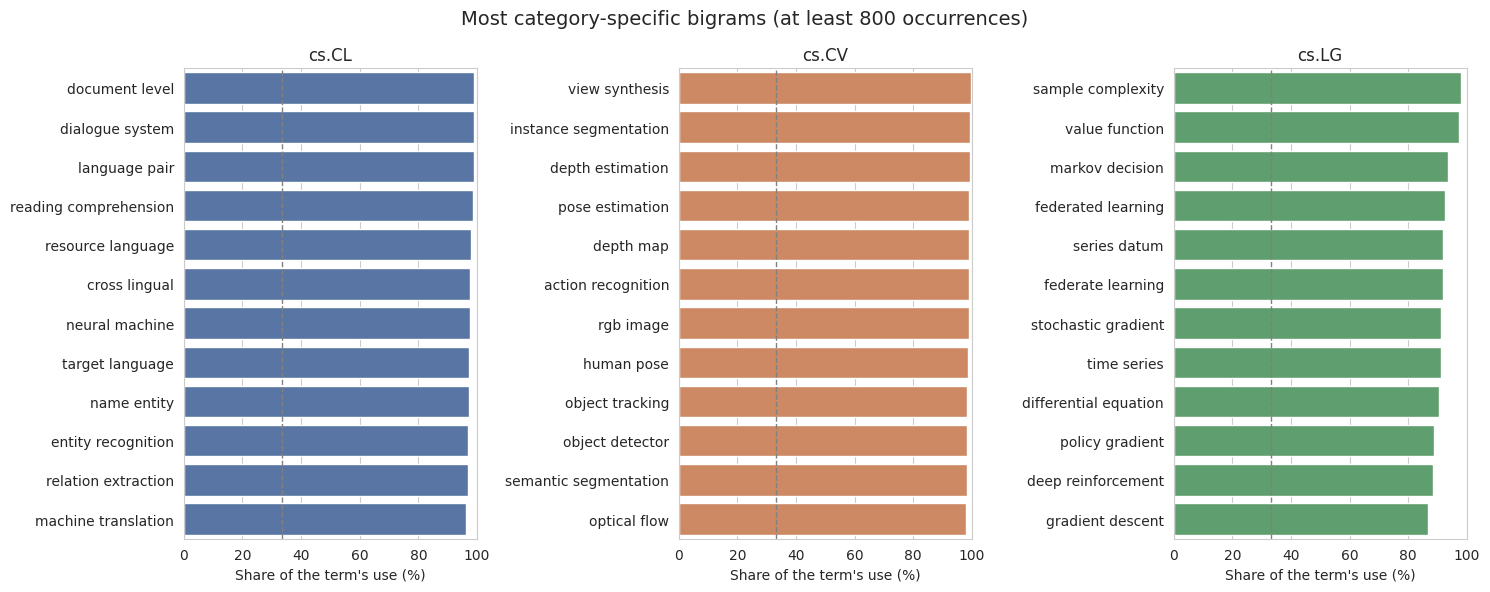

In [21]:
# Bigrams: the most category-specific ones
bi_counts = category_term_counts(2)
top_bi = distinctive_terms(bi_counts, min_total=800)
plot_distinctive(top_bi, "Most category-specific bigrams (at least 800 occurrences)",
                 "per_category_distinctive_bigrams.png")

**Implications for the project:**

- **Class balance:** the cleaned dataset is balanced by design because of the 40k cap, while the real proportions in the original snapshot are uneven (cs.CV 40.89%, cs.LG 37.17%, cs.CL 21.94%, so cs.CV is about 1.86 times cs.CL). No class weighting or oversampling is needed for the balanced sample, but macro-F1 should still be reported. All EDA and modelling conclusions apply to the balanced sample, and any claim about real arXiv class proportions must say that it comes from the uncapped counts and not from the cleaned dataset.
- **Labels and cross-listing:** about 58% of papers list more than one category, so primary_category is a single label for a partly ambiguous problem. Classifier errors should be broken down per class (a confusion matrix), with particular attention to cs.LG against cs.CV and cs.CL, which overlap the most. A multi-label formulation using the full categories field is a possible extension, but would need its own evaluation setup.
- **Text is the main signal:** almost every category-specific term has 85% to 99% of its use in one category, so a TF-IDF baseline with a linear model should have plenty of signal to work with. The most likely errors are on cross-listed papers and on cs.LG, whose distinctive terms are the least exclusive.
- **Vocabulary:** use text_lemma for TF-IDF, LDA and other bag-of-words methods, and text_raw for embeddings. "model", "base" and "datum" are among the most frequent terms in all three categories and carry no category information. TF-IDF down-weights them, and they are worth adding to the stop-word list for topic modelling. Lemmatiser artefacts ("datum", "federate" next to "federated", "pre train") are minor but can be fixed with a small custom mapping.
- **Text length:** abstracts have a median of about 168 words, ranging from about 156 for cs.CL to 177 for cs.CV, so length is only a weak feature. Embedding models that read about 256 tokens will truncate the longer abstracts (slightly more of cs.CV), so fixed-length truncation is a sensible choice, and the few extreme outliers are not a concern.
- **Features:** abstract length, title length, year and number of categories are at most weakly correlated (|r| up to about 0.12), so they can be used together without multicollinearity problems.
- **Trends:** the cleaned sample changes the ranking between categories over time (cs.CL looks largest in 2023 and 2024, but cs.CV is largest in the uncapped data), so claims about publication volume or category mix over time should use the uncapped counts in section 8 (volume grew about 3.9 times from 2018 to 2024, with cs.CL growing fastest). Papers from 2023 and 2024 make up about 45% of the cleaned sample, so reporting accuracy by year is a useful robustness check.